# 6. Regresión: el estrato como número

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** ¿Ayuda tratar el estrato como un número (1 a 6) en vez de como una categoría?

**Respuesta corta.** No para clasificar. El mejor regresor (Random Forest, RMSE 0.57 estratos) comprime los
extremos y, al redondear, su F1 macro queda por debajo del de los clasificadores. Sus residuos están
correlacionados en el espacio: la ubicación deja información sin explicar.
```

La guía pide también 7 modelos de regresión. El problema del proyecto es de clasificación, así que la rama de
regresión se plantea como **la lectura ordinal del mismo problema**: predecir el estrato (1–6) como número y
medir el error en estratos. Así se puede comparar con la clasificación (redondeando la predicción al estrato
más cercano) y responder si tratar el estrato como continuo ayuda. Mismos datos, submuestra y pliegues; el
balanceo no aplica.

## 6.1 Métricas en el bucle externo

In [1]:
import pandas as pd

from _comun import figura, leer_csv, leer_json

RR = leer_csv("resumen_regresion.csv")
AR = leer_json("analisis_regresion.json") or {}
if RR is not None:
    t = RR.copy()
    t.columns = [c.replace("_mean", " (media)").replace("_std", " (desv.)") for c in t.columns]
    display(t.round(4))

,modelo,metodo,rmse (media),rmse (desv.),mae (media),mae (desv.),r2 (media),r2 (desv.),f1_macro_redondeado (media),f1_macro_redondeado (desv.),seg_busqueda (media),seg_busqueda (desv.)
0,Random Forest (regresión),Grid,0.5706,0.1004,0.4320,0.0743,0.8303,0.0715,0.5830,0.0905,376.0797,111.1016
1,Random Forest (regresión),Random,0.5783,0.1054,0.4331,0.0737,0.8242,0.0807,0.5836,0.0633,364.3528,62.9948
2,Random Forest (regresión),Genética,0.5793,0.1066,0.4323,0.0738,0.8237,0.0809,0.5885,0.0675,391.0167,67.0071
3,XGBoost (regresión),Random,0.5809,0.1019,0.4438,0.0774,0.8238,0.0756,0.6027,0.0692,115.8124,13.5476
4,XGBoost (regresión),Bayesiana,0.5830,0.1060,0.4438,0.0813,0.8216,0.0811,0.5702,0.0564,116.0518,7.1118
5,XGBoost (regresión),Genética,0.5881,0.1025,0.4404,0.0755,0.8192,0.0778,0.5848,0.0740,169.5667,15.7016
6,Random Forest (regresión),Bayesiana,0.5936,0.1142,0.4372,0.0844,0.8154,0.0817,0.5954,0.1117,459.6834,179.7294
7,SVR,Random,0.5958,0.0602,0.4626,0.0459,0.8177,0.0552,0.6002,0.0863,87.5135,21.0557
8,SVR,Grid,0.5976,0.0613,0.4615,0.0508,0.8164,0.0570,0.5994,0.0862,178.0523,35.2861
9,SVR,Bayesiana,0.5984,0.0620,0.4706,0.0439,0.8162,0.0554,0.6019,0.0850,187.2957,52.6456


**Lectura.** Los ensambles de árboles vuelven a ganar: Random Forest (RMSE 0.571 ± 0.100 estratos, R² 0.83) y
XGBoost (0.581) van por delante de SVR (0.596), KNN (0.633), los lineales Ridge y Lasso (≈ 0.67,
indistinguibles entre sí y entre optimizadores) y el árbol individual (0.76). Un RMSE de 0.57 quiere decir que
el error típico es de algo más de medio estrato; el MAE, de 0.43 estratos.

Al redondear la predicción al estrato más cercano, el F1 macro de los mejores (0.57 a 0.60) queda por debajo
del de los clasificadores (≈ 0.66, capítulo 5). La causa es que la regresión **comprime los extremos hacia el
centro**: en las predicciones fuera de muestra de Random Forest, las viviendas de estrato 6 reciben en
promedio 5.03 y solo el 19 % se redondea a 6; las de estrato 1 reciben 1.48 (65 % de acierto). La pérdida
cuadrática empuja hacia la media en las clases raras de los extremos, que son justo las que más pesan en el F1
macro. Para este problema, entonces, tratar el estrato como número no mejora la clasificación; sirve como
lectura ordinal del error.

Los tiempos de búsqueda de esta tabla están inflados: por un error de ejecución corrieron dos copias
simultáneas de la regresión, así que solo se pueden comparar entre sí, no con los de clasificación. Aun con
esa salvedad, Ridge con SAGA es el más lento (770 a 910 s por búsqueda) por la convergencia del solver con
regularización débil (capítulo 4).

## 6.2 Entrenamiento, validación y prueba

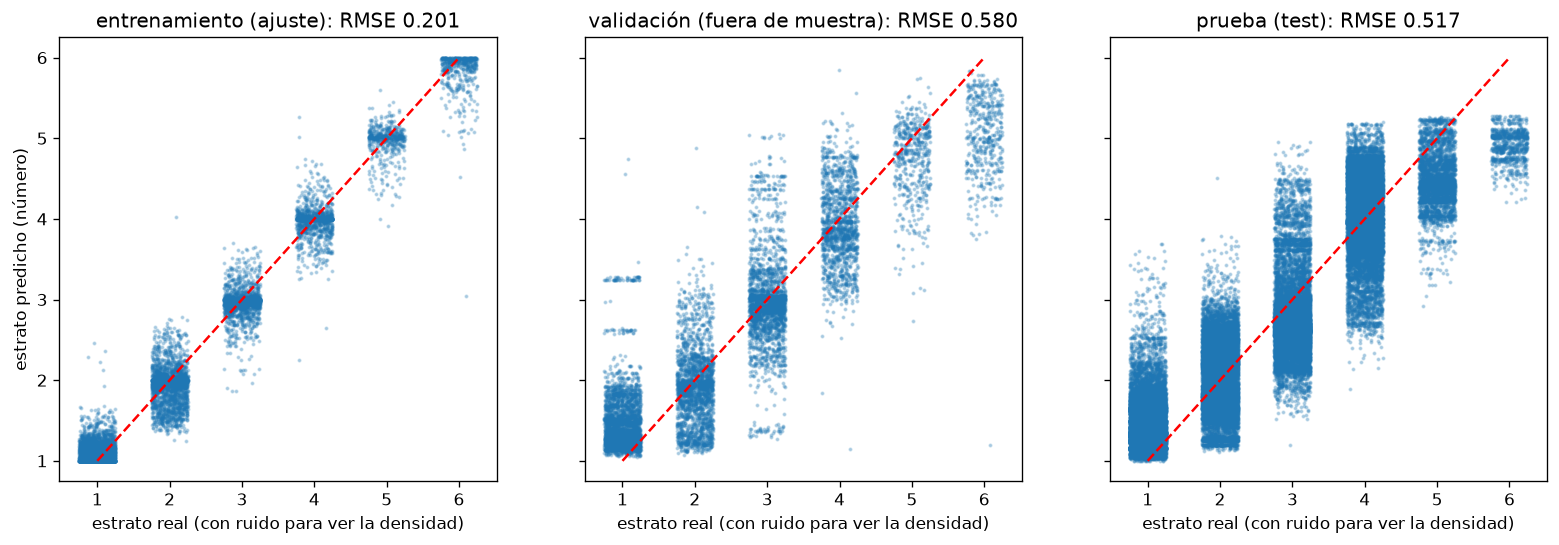

{'modelo': 'Random Forest (regresión) | Grid', 'params': {'n_estimators': 150, 'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 2}, 'rmse': 0.5168115844154807, 'mae': 0.4286304535128251, 'f1_macro_redondeado': 0.520388915152966}


In [2]:
figura("regresion_train_val_test.png")
if AR.get("test_mejor"):
    print(AR["test_mejor"])

## 6.3 Análisis de residuos del mejor modelo

Las pruebas de independencia de la guía (BDS, Ljung-Box, ACF) se diseñaron para series de tiempo. El catastro no
tiene tiempo, así que los residuos se **ordenan en el espacio** (de sur a norte, la dirección del gradiente del
estrato): la «autocorrelación serial» se lee como parecido entre viviendas cercanas en esa dirección. Se
complementa con el I de Moran de los residuos (8 vecinos), la prueba natural de dependencia espacial.

- **White**: H0 = varianza constante de los errores (regresores: predicción y coordenadas).
- **BDS**: H0 = residuos independientes e idénticamente distribuidos (detecta dependencia no lineal).
- **Ljung-Box** (20 rezagos): H0 = sin autocorrelación.

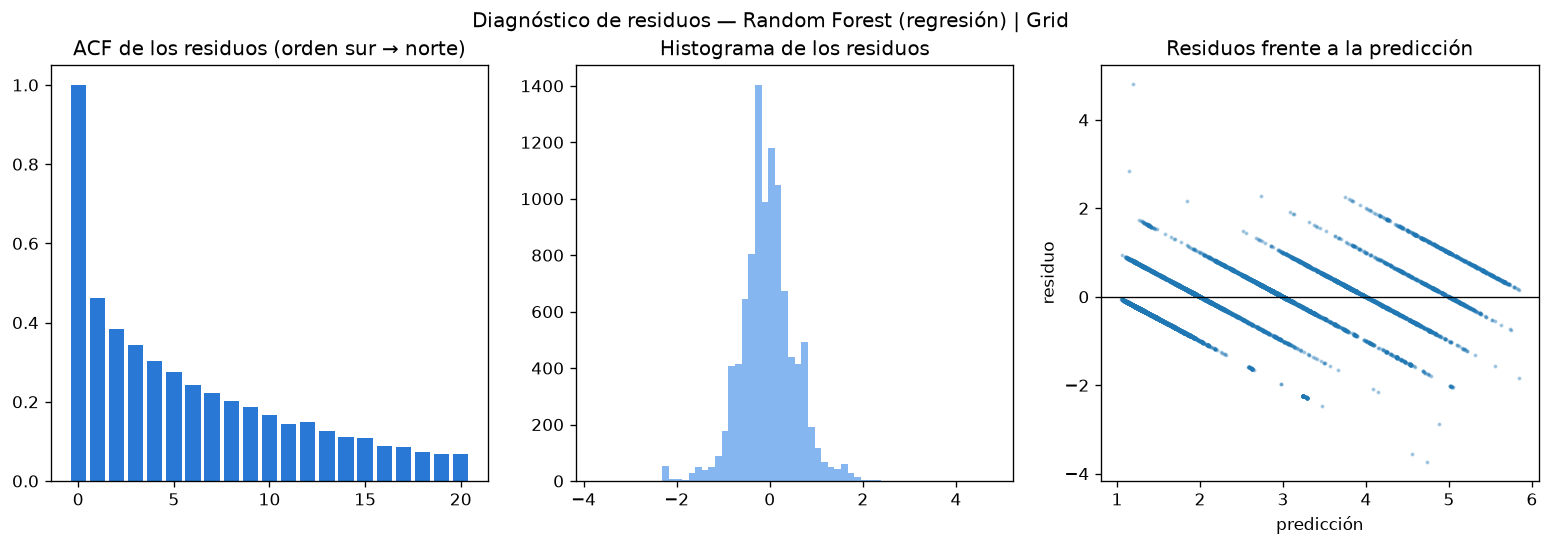

,estadístico,p-valor
White,721.119405,1.990266e-149
BDS (dim. 2),20.211913,7.690874e-91
Ljung-Box (20),9687.879940,0.000000e+00
asimetría / D'Agostino,-0.020295,4.425040e-120
I de Moran,0.346160,NaN


In [3]:
figura("residuos_regresion.png")
if AR.get("supuestos_mejor"):
    s = AR["supuestos_mejor"]
    display(pd.DataFrame({"estadístico": [s.get("white", {}).get("lm"), s["bds"]["estadistico_dim2"],
                                          s["ljung_box"]["q"], s["normalidad"]["asimetria"], s["moran_residuos_k8"]],
                          "p-valor": [s.get("white", {}).get("p"), s["bds"]["p_dim2"], s["ljung_box"]["p"],
                                      s["normalidad"]["p_dagostino"], None]},
                         index=["White", "BDS (dim. 2)", "Ljung-Box (20)", "asimetría / D'Agostino", "I de Moran"]))

**Lectura.** Los residuos del mejor modelo (Random Forest con Grid) no cumplen ningún supuesto clásico. White
rechaza la varianza constante (LM = 721, p ≈ 10⁻¹⁴⁹); BDS y Ljung-Box rechazan la independencia (p ≈ 0); la
autocorrelación en el orden sur → norte es 0.46 en el primer rezago y decae despacio (0.30 en el cuarto, 0.07
en el vigésimo). El I de Moran de los residuos con 8 vecinos es 0.35: viviendas vecinas comparten el error.
Las colas son más pesadas que las de una normal (curtosis en exceso 2.3), aunque la distribución es simétrica
(asimetría −0.02).

Esto importa para el proyecto por dos razones. Primero, aun con la vecindad física de 8 vecinos como
variables, queda estructura espacial sin explicar en el error: es justo lo que el XGBoost geográfico intenta
capturar con modelos locales. Segundo, como los errores no son independientes, las pruebas e intervalos deben
remuestrear bloques espaciales (capítulo 7), no viviendas sueltas.